# SP-004 — DJD-1/3

DJD propone grupos de una a tres piezas; el raster valida cada colocación. La tolerancia experimental `w` parte de 1/20 del área nominal, según la fuente académica.

Configuración TA-027: raster 1 mm, giros 5°; SMALL margen/separación 0/0 mm y MEDIUM/COMPLEX 1/1 mm. Prioridad retazo → plancha.

## Preparación del entorno

In [1]:
# Importamos Path para resolver rutas tanto en local como en Colab.
from pathlib import Path
# Importamos sys para agregar el backend al path de imports.
import sys
# Importamos JSON para leer la instancia discriminante.
import json
# Usamos Decimal en límites y áreas de configuración.
from decimal import Decimal
# Tomamos el directorio actual como raíz candidata.
repo_root = Path.cwd()
# Comprobamos que la carpeta actual contenga los fixtures.
if not (repo_root / "experiments/optimization/loader.py").exists():
    # Usamos la ubicación sugerida para clonar el repositorio en Colab.
    repo_root = Path("/content/NewGlass")
# Detenemos con instrucción legible si falta el repo.
if not (repo_root / "experiments/optimization/loader.py").exists():
    # Explicamos cómo preparar Colab.
    raise RuntimeError("Clona NewGlass en /content/NewGlass o ejecuta desde la raíz del repositorio.")
# Habilitamos los imports app del motor actual.
sys.path.insert(0, str(repo_root / "backend"))
# Habilitamos imports del loader y del experimento.
sys.path.insert(0, str(repo_root))
# Reutilizamos la lista y loader TA-027.
from experiments.optimization.loader import CASES, load_problem, read_case
# Importamos la política aislada DJD.
from experiments.optimization.djd import DJDExperimental
# Reutilizamos el ejecutor secuencial.
from experiments.optimization.djd.run_benchmark import DISCRIMINANT, METHODS, load_experimental_case, run_one
# Confirmamos la raíz que usa el notebook.
print("Repositorio:", repo_root)
# Confirmamos métodos y modo de recursos.
print("Métodos:", [name for name, _ in METHODS], "| multiprocessing: no")

Repositorio: C:\Users\patri\GitHub\optimizador-vidrio
Métodos: ['FF', 'BF', 'WF', 'DJD-1/3'] | multiprocessing: no


**Interpretación:** El notebook usa una copia del repositorio y no necesita acceso a base de datos; métodos ejecutan uno por uno.

## Validación de fixtures

Ejecuta el paso experimental y muestra su salida guardada.

In [2]:
# Creamos un resumen de entradas para las celdas siguientes.
fixture_data = {}
# Recorremos los tres fixtures oficiales en su orden estable.
for case_id in CASES:
    # Leemos una copia del JSON oficial.
    data = read_case(case_id)
    # Guardamos datos sin escribirlos al archivo.
    fixture_data[case_id] = data
    # Mostramos los parámetros originales.
    print(case_id, "filas de piezas:", len(data["pieces"]), "fuentes:", len(data["stock"]), "config:", data["config"])
# Localizamos el caso no oficial.
discriminant_path = repo_root / "experiments/optimization/djd/cases/DJD-DISCRIMINANT-001.json"
# Leemos su etiqueta y configuración.
discriminant_data = json.loads(discriminant_path.read_text(encoding="utf-8"))
# Separamos explícitamente el caso didáctico.
print(discriminant_data["label"], "filas:", len(discriminant_data["pieces"]))

EXP-SMALL-001 filas de piezas: 1 fuentes: 2 config: {'resolution_mm': 1, 'angular_step_deg': 5, 'margin_mm': 0, 'separation_mm': 0}
EXP-MEDIUM-001 filas de piezas: 3 fuentes: 3 config: {'resolution_mm': 1, 'angular_step_deg': 5, 'margin_mm': 1, 'separation_mm': 1}
EXP-COMPLEX-001 filas de piezas: 6 fuentes: 5 config: {'resolution_mm': 1, 'angular_step_deg': 5, 'margin_mm': 1, 'separation_mm': 1}
CASO DE DISCRIMINACIÓN HEURÍSTICA — NO FORMA PARTE DE TA-027 filas: 3


**Interpretación:** Los tres fixtures oficiales continúan intactos; el JSON discriminante está en el directorio de DJD.

## EXP-SMALL-001

Ejecuta el paso experimental y muestra su salida guardada.

In [3]:
# Reutilizamos la entrada oficial y la construcción de snapshots.
small_data, small_problem = load_experimental_case("EXP-SMALL-001")
# Contamos las unidades físicas solicitadas.
print("unidades expandidas:", len(small_problem.units))
# Confirmamos separación por compatibilidad.
print("grupos material-espesor:", len(small_problem.groups))

unidades expandidas: 3
grupos material-espesor: 1


**Interpretación:** SMALL tiene tres unidades de una geometría y fuentes retazo/plancha del mismo material.

## EXP-MEDIUM-001

Ejecuta el paso experimental y muestra su salida guardada.

In [4]:
# Creamos snapshots nuevos de MEDIUM.
medium_data, medium_problem = load_experimental_case("EXP-MEDIUM-001")
# Contamos piezas individuales después de expandir cantidades.
print("unidades expandidas:", len(medium_problem.units))
# Contamos fuentes compatibles.
print("fuentes físicas:", sum(len(group.stock_candidates) for group in medium_problem.groups))

unidades expandidas: 9
fuentes físicas: 4


**Interpretación:** MEDIUM contiene nueve unidades; el loader mantiene material y espesor como clave de agrupación.

## EXP-COMPLEX-001

Ejecuta el paso experimental y muestra su salida guardada.

In [5]:
# Reconstruimos COMPLEX con el loader congelado.
complex_data, complex_problem = load_experimental_case("EXP-COMPLEX-001")
# Informamos la carga del pedido.
print("unidades expandidas:", len(complex_problem.units))
# Contamos grupos compatibles.
print("grupos material-espesor:", len(complex_problem.groups))
# Informamos unidades de inventario.
print("fuentes físicas:", sum(len(group.stock_candidates) for group in complex_problem.groups))

unidades expandidas: 24
grupos material-espesor: 2
fuentes físicas: 7


**Interpretación:** COMPLEX tiene 24 unidades y cinco grupos de compatibilidad; DJD reinicia su fuente activa dentro de cada grupo.

## Orden de piezas

Ejecuta el paso experimental y muestra su salida guardada.

In [6]:
# Registramos el orden de filas original.
before = [(row["id_pieza"], row["cantidad"]) for row in medium_data["pieces"]]
# Aplicamos orden decreciente de área con IDs estables.
ordered_units = sorted(medium_problem.units, key=lambda unit: (-unit.area_mm2, unit.piece_id, unit.unit_index, unit.order_id))
# Mostramos el JSON como fue entregado.
print("ANTES:", before)
# Mostramos unidades expandidas y áreas.
print("DJD:", [(u.piece_id, u.unit_index, str(u.area_mm2)) for u in ordered_units])

ANTES: [(1, 3), (2, 4), (3, 2)]
DJD: [(1, 1, '18.00'), (1, 2, '18.00'), (1, 3, '18.00'), (3, 1, '12.57'), (3, 2, '12.57'), (2, 1, '6.00'), (2, 2, '6.00'), (2, 3, '6.00'), (2, 4, '6.00')]


**Interpretación:** La selección combinatoria es determinista; los desempates estables evitan depender del orden del diccionario.

## Llenado inicial hasta 1/3

Ejecuta el paso experimental y muestra su salida guardada.

In [7]:
# Ejecutamos el caso pequeño desde el benchmark real.
disc_row, disc_detail = run_one(DISCRIMINANT, "DJD-1/3", DJDExperimental)
# Extraemos los diagnósticos producidos por DJD.
disc_trace = disc_detail["djd_trace"]
# Recorremos las fuentes realmente activadas.
for ratio in disc_trace["initial_fill_ratio"]:
    # Mostramos capacidad nominal y ocupación del llenado largest-first.
    print(ratio)

{'source': 'PLANCHA', 'material_id': 901, 'physical_unit_index': 1, 'ratio': '0.4', 'initial_capacity_mm2': '100.00'}


**Interpretación:** La fuente inicia la búsqueda combinatoria tras superar el tercio; el ratio usa el área nominal total y el placement sigue validando el layout raster.

## Combinaciones de una pieza

Ejecuta el paso experimental y muestra su salida guardada.

In [8]:
# Leemos los singles visitados en el caso didáctico.
print("subconjuntos tamaño 1:", disc_trace["combinations_size_1"])
# Mostramos los singles excluidos por capacidad o tolerancia.
print("podas de tamaño 1:", disc_trace["pruned_by_size"][1])

subconjuntos tamaño 1: 5
podas de tamaño 1: 4


**Interpretación:** Los singles que no dejan residuo dentro de w se descartan antes de pedir una búsqueda geométrica.

## Combinaciones de dos piezas

Ejecuta el paso experimental y muestra su salida guardada.

In [9]:
# Mostramos los pares no ordenados visitados.
print("subconjuntos tamaño 2:", disc_trace["combinations_size_2"])
# Recorremos los grupos realmente aceptados.
for group in disc_trace["selected_groups"]:
    # Aislamos la decisión emparejada.
    if group["size"] == 2:
        # Mostramos IDs, tolerancia y residuo estimado.
        print(group)

subconjuntos tamaño 2: 2
{'source': 'PLANCHA', 'material_id': 901, 'size': 2, 'piece_ids': [2, 3], 'unit_ids': [[2, 1], [3, 1]], 'waste_tolerance_mm2': '5.00', 'estimated_residual_mm2': '5.00'}


**Interpretación:** El grupo de dos piezas es una decisión registrada por el algoritmo, no un resultado inventado a partir de la demo.

## Combinaciones de tres piezas

Ejecuta el paso experimental y muestra su salida guardada.

In [10]:
# Leemos la cuenta de ternas del caso discriminante.
print("demo, ternas generadas:", disc_trace["combinations_size_3"])
# Revisamos el contador de cada fixture oficial.
for case_id in CASES:
    # Ejecutamos cada caso por separado.
    row, detail = run_one(case_id, "DJD-1/3", DJDExperimental)
    # Informamos el contador real.
    print(case_id, "ternas:", detail["djd_trace"]["combinations_size_3"])
    # Liberamos detalles antes de cargar la siguiente instancia.
    del row, detail

demo, ternas generadas: 0
EXP-SMALL-001 ternas: 0
EXP-MEDIUM-001 ternas: 634
EXP-COMPLEX-001 ternas: 18493


**Interpretación:** El número de ternas depende del stock y de los candidatos que sobreviven a la poda; no se fuerza una selección de tamaño tres.

## Tolerancia w

Ejecuta el paso experimental y muestra su salida guardada.

In [11]:
# Importamos Fraction para mostrar exactamente 1/20.
from fractions import Fraction
# Fijamos el incremento relativo recomendado en la adaptación 2D.
waste_fraction = Fraction(1, 20)
# Leemos la capacidad usada por la fuente de la demo.
capacity = Decimal(disc_trace["initial_fill_ratio"][0]["initial_capacity_mm2"])
# Mostramos el parámetro exacto y visible.
print("fracción incremental:", waste_fraction)
# Calculamos el valor según el área nominal total.
print("incremento mm²:", capacity * Decimal(waste_fraction.numerator) / Decimal(waste_fraction.denominator))
# Reportamos el número real de relajaciones.
print("pasos usados:", disc_trace["waste_tolerance_steps"])

fracción incremental: 1/20
incremento mm²: 5.00
pasos usados: 1


**Interpretación:** En la fuente de 100 mm² el paso es 5 mm²; la búsqueda necesitó un incremento para aceptar B+C.

## Validación geométrica

Ejecuta el paso experimental y muestra su salida guardada.

In [12]:
# Contamos órdenes que llegan a geometría.
print("secuencias con chequeo geométrico:", disc_trace["geometric_sequence_checks"])
# Contamos pruebas individuales de placement.
print("chequeos pieza-layout:", disc_trace["geometric_checks"])
# Contamos grupos completos aceptables geométricamente.
print("secuencias factibles:", disc_trace["feasible_combinations"])
# Mostramos poda por fallos ya conocidos en el mismo layout.
print("secuencias fallidas reutilizadas:", disc_trace["cached_sequences_skipped"])

secuencias con chequeo geométrico: 1
chequeos pieza-layout: 3
secuencias factibles: 1
secuencias fallidas reutilizadas: 0


**Interpretación:** Una secuencia solo se conserva si cada pieza entra en un layout temporal que incluye las anteriores del grupo.

## DEMO DIDÁCTICA — NO PERTENECE AL BENCHMARK OFICIAL

Ejecuta el paso experimental y muestra su salida guardada.

In [13]:
# Enumeramos grupos de ejemplo con distintos tamaños.
demo_candidates = [("B",), ("B", "C"), ("B", "D"), ("C", "D"), ("B", "D", "E")]
# Recorremos los ejemplos didácticos en orden explícito.
for group in demo_candidates:
    # Mostramos piezas que podrían validarse como secuencia.
    print(" + ".join(group))

B
B + C
B + D
C + D
B + D + E


**Interpretación:** La lista solo explica la unidad de decisión; la factibilidad benchmark se obtiene de NewGlass y no de esta enumeración didáctica.

## DJD SMALL

Ejecuta el paso experimental y muestra su salida guardada.

In [14]:
# Corremos DJD con métricas oficiales.
small_djd_row, small_djd_detail = run_one("EXP-SMALL-001", "DJD-1/3", DJDExperimental)
# Guardamos la traza diagnóstica.
small_djd_trace = small_djd_detail["djd_trace"]
# Mostramos unidades colocadas.
print("cobertura:", small_djd_row["placed_units"], "/", small_djd_row["requested_units"])
# Mostramos fase inicial y combinaciones posteriores.
print("grupos seleccionados:", small_djd_trace["selected_combination_sizes"])

cobertura: 3 / 3
grupos seleccionados: (1, 1, 1)


**Interpretación:** SMALL completa sus tres unidades con una fuente de cada tipo; el llenado inicial consume el retazo y los singles siguientes completan el pedido.

## FF/BF/WF SMALL

Ejecuta el paso experimental y muestra su salida guardada.

In [15]:
# Creamos una lista corta para guardar los tres resultados medidos.
small_baselines = []
# Recorremos FF, BF y WF en ese orden.
for method_name, optimizer_class in METHODS[:3]:
    # Ejecutamos un baseline sobre snapshots nuevos.
    row, detail = run_one("EXP-SMALL-001", method_name, optimizer_class)
    # Guardamos métricas comparables y duración.
    small_baselines.append(row)
    # Mostramos la salida observada.
    print(method_name, row["placed_units"], "/", row["requested_units"], "utilización", row["utilization_pct"])
    # Liberamos la traza de placements antes del próximo método.
    del detail

FF 3 / 3 utilización 60.000
BF 3 / 3 utilización 60.000
WF 3 / 3 utilización 60.000


**Interpretación:** Los tres baselines también colocan las tres unidades; la comparación se completa con el conteo de fuentes y merma.

## Comparación SMALL

Ejecuta el paso experimental y muestra su salida guardada.

In [16]:
# Unimos baselines y DJD en la misma tabla.
small_comparison = small_baselines + [small_djd_row]
# Recorremos cada observación del fixture.
for row in small_comparison:
    # Imprimimos columnas comparables.
    print(row["method"], row["placed_units"], row["remnants_used"], row["sheets_used"], row["utilization_pct"], row["waste"], row["runtime_ms"])

FF 3 1 1 60.000 0.00 10.874
BF 3 1 1 60.000 0.00 13.792
WF 3 1 1 60.000 0.00 12.049
DJD-1/3 3 1 1 60.000 0.00 1.113


**Interpretación:** SMALL puede coincidir porque es homogéneo; esto no invalida los diagnósticos de DJD.

## DJD MEDIUM

Ejecuta el paso experimental y muestra su salida guardada.

In [17]:
# Medimos DJD en el caso medio.
medium_djd_row, medium_djd_detail = run_one("EXP-MEDIUM-001", "DJD-1/3", DJDExperimental)
# Extraemos contadores de combinaciones.
medium_djd_trace = medium_djd_detail["djd_trace"]
# Reportamos colocación.
print("cobertura:", medium_djd_row["placed_units"], "/", medium_djd_row["requested_units"])
# Exponemos tamaños elegidos.
print("grupos seleccionados:", medium_djd_trace["selected_combination_sizes"])
# Contrastamos costo y poda.
print("podas/geometría:", medium_djd_trace["combinations_pruned"], medium_djd_trace["geometric_checks"])

cobertura: 9 / 9
grupos seleccionados: (1, 1, 1, 1, 1, 1, 1, 1, 1)
podas/geometría: 983 582


**Interpretación:** DJD completa MEDIUM; las combinaciones generadas y podadas explican el costo más allá del runtime.

## FF/BF/WF MEDIUM

Ejecuta el paso experimental y muestra su salida guardada.

In [18]:
# Inicializamos resultados resumidos de MEDIUM.
medium_baselines = []
# Conservamos orden serial FF, BF y WF.
for method_name, optimizer_class in METHODS[:3]:
    # Ejecutamos el baseline una sola vez.
    row, detail = run_one("EXP-MEDIUM-001", method_name, optimizer_class)
    # Guardamos métricas y tiempo.
    medium_baselines.append(row)
    # Informamos la salida.
    print(method_name, row["placed_units"], row["remnants_used"], row["sheets_used"], row["utilization_pct"])
    # Liberamos placements serializados.
    del detail

FF 9 2 1 28.413
BF 9 2 1 28.413
WF 9 2 2 18.584


**Interpretación:** Los baselines se ejecutan después de DJD y comienzan desde problemas recién cargados.

## Comparación MEDIUM

Ejecuta el paso experimental y muestra su salida guardada.

In [19]:
# Unimos cuatro filas para MEDIUM.
medium_comparison = medium_baselines + [medium_djd_row]
# Recorremos los resultados medidos.
for row in medium_comparison:
    # Mostramos métricas oficiales.
    print(row["method"], row["placed_units"], row["remnants_used"], row["sheets_used"], row["utilization_pct"], row["waste"], row["runtime_ms"])

FF 9 2 1 28.413 201.86 19.393
BF 9 2 1 28.413 193.86 26.780
WF 9 2 2 18.584 301.86 21.896
DJD-1/3 9 2 1 28.413 201.86 163.235


**Interpretación:** La coincidencia o diferencia se informa desde las métricas reales; no se espera que DJD gane por definición.

## DJD COMPLEX

Ejecuta el paso experimental y muestra su salida guardada.

In [20]:
# Ejecutamos el caso complejo.
complex_djd_row, complex_djd_detail = run_one("EXP-COMPLEX-001", "DJD-1/3", DJDExperimental)
# Guardamos la traza experimental.
complex_djd_trace = complex_djd_detail["djd_trace"]
# Informamos unidades colocadas.
print("cobertura:", complex_djd_row["placed_units"], "/", complex_djd_row["requested_units"])
# Mostramos conteos de subconjuntos.
print("generadas:", [complex_djd_trace[f"combinations_size_{size}"] for size in (1, 2, 3)])
# Mostramos trabajo evitado y ejecutado.
print("podadas/geometría:", complex_djd_trace["combinations_pruned"], complex_djd_trace["geometric_checks"])

cobertura: 24 / 24
generadas: [791, 4409, 18493]
podadas/geometría: 13813 7587


**Interpretación:** La traza identifica qué porción del trabajo de DJD terminó en geometría costosa.

## FF/BF/WF COMPLEX

Ejecuta el paso experimental y muestra su salida guardada.

In [21]:
# Guardamos solo filas métricas compactas.
complex_baselines = []
# Mantenemos el orden de control FF, BF y WF.
for method_name, optimizer_class in METHODS[:3]:
    # Cargamos y ejecutamos una entrada nueva.
    row, detail = run_one("EXP-COMPLEX-001", method_name, optimizer_class)
    # Retenemos métricas y tiempo.
    complex_baselines.append(row)
    # Informamos cobertura y planchas.
    print(method_name, row["placed_units"], row["sheets_used"], row["utilization_pct"])
    # Soltamos la serialización detallada para limitar memoria.
    del detail

FF 24 3 29.598
BF 24 3 29.598
WF 24 4 25.309


**Interpretación:** Todos los baselines terminan antes de pasar a la comparación final.

## Comparación COMPLEX

Ejecuta el paso experimental y muestra su salida guardada.

In [22]:
# Juntamos FF, BF, WF y DJD.
complex_comparison = complex_baselines + [complex_djd_row]
# Leemos las cuatro observaciones.
for row in complex_comparison:
    # Mostramos datos reales.
    print(row["method"], row["placed_units"], row["remnants_used"], row["sheets_used"], row["utilization_pct"], row["waste"], row["runtime_ms"])

FF 24 3 3 29.598 746.72 93.125
BF 24 3 3 29.598 746.72 93.525
WF 24 3 4 25.309 886.72 90.384
DJD-1/3 24 3 3 29.598 746.72 6187.963


**Interpretación:** La diferencia se evalúa con placements y trazas además de las métricas agregadas.

## Determinismo SMALL ×3

Ejecuta el paso experimental y muestra su salida guardada.

In [23]:
# Definimos una firma estable de placements y decisiones.
def djd_signature(case_id):
    # Ejecutamos DJD sobre snapshots nuevos.
    row, detail = run_one(case_id, "DJD-1/3", DJDExperimental)
    # Extraemos los diagnósticos deterministas.
    trace = detail["djd_trace"]
    # Normalizamos placements.
    placements = tuple((item["piece_id"], item["unit_index"], item["source"], item["material_id"], item["x_mm"], item["y_mm"], item["rotation_deg"]) for item in detail["placements"])
    # Excluimos duraciones.
    decision = (tuple(trace["selected_combination_sizes"]), tuple(tuple(group["unit_ids"]) for group in trace["selected_groups"] if "unit_ids" in group), trace["source_switches"])
    # Devolvemos solo decisiones repetibles.
    return placements, decision
# Hacemos tres corridas independientes.
small_signatures = [djd_signature("EXP-SMALL-001") for _ in range(3)]
# Comparamos las tres salidas.
print("PASS" if small_signatures[0] == small_signatures[1] == small_signatures[2] else "FAIL")

PASS


**Interpretación:** La verificación cubre placements, rotaciones, grupos elegidos y cambios de fuente.

## Determinismo MEDIUM ×3

Ejecuta el paso experimental y muestra su salida guardada.

In [24]:
# Repetimos MEDIUM en ejecuciones independientes.
medium_signatures = [djd_signature("EXP-MEDIUM-001") for _ in range(3)]
# Confirmamos orden, grupos y placements.
print("PASS" if medium_signatures[0] == medium_signatures[1] == medium_signatures[2] else "FAIL")

PASS


**Interpretación:** El runtime puede variar y queda fuera de la firma de determinismo.

## Determinismo COMPLEX ×3

Ejecuta el paso experimental y muestra su salida guardada.

In [25]:
# Repetimos la instancia compleja tres veces.
complex_signatures = [djd_signature("EXP-COMPLEX-001") for _ in range(3)]
# Validamos igualdad estructural.
print("PASS" if complex_signatures[0] == complex_signatures[1] == complex_signatures[2] else "FAIL")

PASS


**Interpretación:** PASS significa que las tres corridas generaron las mismas decisiones.

## Tabla consolidada

Ejecuta el paso experimental y muestra su salida guardada.

In [26]:
# Importamos csv para leer los 16 resultados guardados.
import csv
# Construimos la ruta del benchmark.
csv_path = repo_root / "docs/evidence/sprint-02/SP-004/benchmark-results/sp004_djd_results.csv"
# Abrimos el CSV sin alterar sus filas.
with csv_path.open(encoding="utf-8", newline="") as stream:
    # Convertimos el archivo en filas con nombre.
    consolidated = list(csv.DictReader(stream))
# Recorremos TA-027 y el caso didáctico por separado.
for row in consolidated:
    # Mostramos métricas oficiales.
    print(row["case"], row["method"], row["requested_units"], row["placed_units"], row["remnants_used"], row["sheets_used"], row["utilization_pct"], row["waste"], row["runtime_ms"])

EXP-SMALL-001 FF 3 3 1 1 60.000 0.00 20.495
EXP-SMALL-001 BF 3 3 1 1 60.000 0.00 19.392
EXP-SMALL-001 WF 3 3 1 1 60.000 0.00 17.958
EXP-SMALL-001 DJD-1/3 3 3 1 1 60.000 0.00 2.411
EXP-MEDIUM-001 FF 9 9 2 1 28.413 201.86 30.501
EXP-MEDIUM-001 BF 9 9 2 1 28.413 193.86 44.089
EXP-MEDIUM-001 WF 9 9 2 2 18.584 301.86 29.752
EXP-MEDIUM-001 DJD-1/3 9 9 2 1 28.413 201.86 267.294
EXP-COMPLEX-001 FF 24 24 3 3 29.598 746.72 154.009
EXP-COMPLEX-001 BF 24 24 3 3 29.598 746.72 168.081
EXP-COMPLEX-001 WF 24 24 3 4 25.309 886.72 159.980
EXP-COMPLEX-001 DJD-1/3 24 24 3 3 29.598 746.72 7693.620
DJD-DISCRIMINANT-001 FF 3 3 0 1 95.000 0.00 1.932
DJD-DISCRIMINANT-001 BF 3 3 0 1 95.000 0.00 1.455
DJD-DISCRIMINANT-001 WF 3 3 0 1 95.000 0.00 1.450
DJD-DISCRIMINANT-001 DJD-1/3 3 3 0 1 95.000 0.00 1.466


**Interpretación:** Las cuatro filas del caso discriminante se identifican por su case ID y no se agregan a TA-027.

## Número de combinaciones

Ejecuta el paso experimental y muestra su salida guardada.

In [27]:
# Recorremos fixtures oficiales y caso adicional.
for case_id in (*CASES, DISCRIMINANT):
    # Seleccionamos la fila DJD.
    row = next(item for item in consolidated if item["case"] == case_id and item["method"] == "DJD-1/3")
    # Mostramos contadores.
    print(case_id, "grupos 1/2/3:", row["combinations_size_1"], row["combinations_size_2"], row["combinations_size_3"], "podados:", row["combinations_pruned"], "secuencias geométricas:", row["geometric_sequence_checks"], "checks pieza:", row["geometric_checks"], "factibles:", row["feasible_combinations"])

EXP-SMALL-001 grupos 1/2/3: 3 0 0 podados: 0 secuencias geométricas: 0 checks pieza: 3 factibles: 0
EXP-MEDIUM-001 grupos 1/2/3: 214 471 634 podados: 983 secuencias geométricas: 397 checks pieza: 582 factibles: 1
EXP-COMPLEX-001 grupos 1/2/3: 791 4409 18493 podados: 13813 secuencias geométricas: 7527 checks pieza: 7587 factibles: 1
DJD-DISCRIMINANT-001 grupos 1/2/3: 5 2 0 podados: 5 secuencias geométricas: 1 checks pieza: 3 factibles: 1


**Interpretación:** Los contadores se acumulan por los pasos de tolerancia; las permutaciones se contabilizan como secuencias geométricas.

## Aprovechamiento

Ejecuta el paso experimental y muestra su salida guardada.

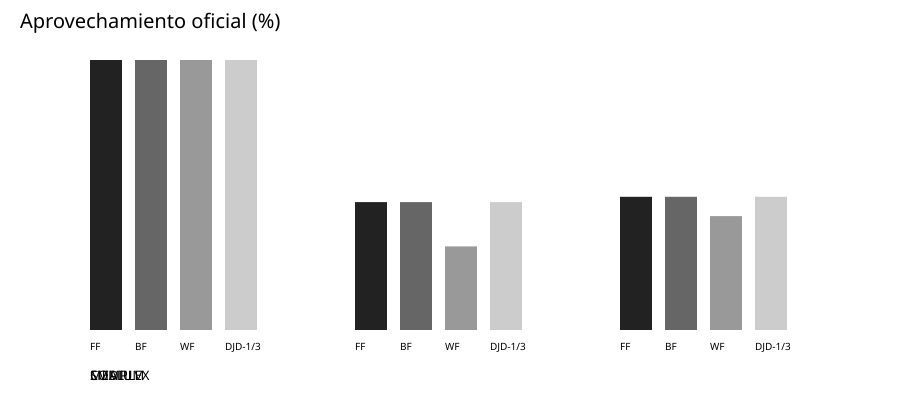

In [28]:
# Define un gráfico vectorial sencillo sin dependencias de plotting.
def svg_bars(rows, metric, title):
    # Fijamos únicamente los IDs oficiales de TA-027.
    cases = list(CASES)
    # Definimos orden de métodos.
    methods = ["FF", "BF", "WF", "DJD-1/3"]
    # Usamos fondo blanco y escala de grises.
    shades = ["#222222", "#666666", "#999999", "#cccccc"]
    # Seleccionamos un tamaño de lectura para Colab.
    width, height = 900, 410
    # Calculamos una escala global de los fixtures.
    maximum = max(float(row[metric]) for row in rows if row["case"] in cases) or 1
    # Iniciamos un canvas blanco.
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}">', '<rect width="100%" height="100%" fill="white"/>']
    # Rotulamos el gráfico.
    parts.append(f'<text x="20" y="28" font-family="sans-serif" font-size="20">{title}</text>')
    # Recorremos cada caso oficial.
    for case_index, case in enumerate(cases):
        # Recorremos los métodos en orden fijo.
        for method_index, method in enumerate(methods):
            # Encontramos la métrica real.
            row = next(item for item in rows if item["case"] == case and item["method"] == method)
            # Convertimos el campo CSV a número para escalarlo.
            value = float(row[metric])
            # Aplicamos una escala común para todas las barras.
            bar_height = value * 270 / maximum
            # Ubicamos la barra dentro del grupo.
            x = 90 + case_index * 265 + method_index * 45
            # Dibujamos la barra gris.
            parts.append(f'<rect x="{x}" y="{330-bar_height:.1f}" width="32" height="{bar_height:.1f}" fill="{shades[method_index]}"/>')
            # Añadimos etiqueta de método.
            parts.append(f'<text x="{x}" y="350" font-family="sans-serif" font-size="10">{method}</text>')
        # Etiquetamos el fixture.
        parts.append(f'<text x="90" y="380" font-family="sans-serif" font-size="13">{case.replace("EXP-", "").replace("-001", "")}</text>')
    # Cerramos la imagen vectorial.
    parts.append('</svg>')
    # Devolvemos la salida que guardará el notebook.
    return "".join(parts)
# Excluimos la demo del análisis TA-027.
official_rows = [row for row in consolidated if row["case"] in CASES]
# Generamos comparación de utilización.
utilization_chart = svg_bars(official_rows, "utilization_pct", "Aprovechamiento oficial (%)")
# El constructor guarda este texto como salida SVG renderizable.
print(utilization_chart)

**Interpretación:** El gráfico describe las métricas obtenidas y no predice resultados de otras órdenes.

## Fuentes utilizadas

Ejecuta el paso experimental y muestra su salida guardada.

In [29]:
# Recorremos las métricas oficiales para detallar cada tipo de fuente.
for row in official_rows:
    # Reportamos inventario consumido.
    print(row["case"], row["method"], "retazos:", row["remnants_used"], "planchas:", row["sheets_used"])

EXP-SMALL-001 FF retazos: 1 planchas: 1
EXP-SMALL-001 BF retazos: 1 planchas: 1
EXP-SMALL-001 WF retazos: 1 planchas: 1
EXP-SMALL-001 DJD-1/3 retazos: 1 planchas: 1
EXP-MEDIUM-001 FF retazos: 2 planchas: 1
EXP-MEDIUM-001 BF retazos: 2 planchas: 1
EXP-MEDIUM-001 WF retazos: 2 planchas: 2
EXP-MEDIUM-001 DJD-1/3 retazos: 2 planchas: 1
EXP-COMPLEX-001 FF retazos: 3 planchas: 3
EXP-COMPLEX-001 BF retazos: 3 planchas: 3
EXP-COMPLEX-001 WF retazos: 3 planchas: 4
EXP-COMPLEX-001 DJD-1/3 retazos: 3 planchas: 3


**Interpretación:** Las fuentes utilizadas se reportan por tipo y caso; la política común conserva retazo antes que plancha.

## Tiempo computacional

Ejecuta el paso experimental y muestra su salida guardada.

In [30]:
# Generamos las barras de tiempo con escala compartida.
runtime_chart = svg_bars(official_rows, "runtime_ms", "Tiempo observado por ejecución (ms)")
# Embebemos el gráfico como SVG.
print(runtime_chart)
# Recorremos solamente TA-027 para leer tolerancia.
for case_id in CASES:
    # Seleccionamos DJD.
    row = next(item for item in consolidated if item["case"] == case_id and item["method"] == "DJD-1/3")
    # Informamos costo y relajaciones.
    print(case_id, "pasos de w:", row["waste_tolerance_steps"], "tiempo ms:", row["runtime_ms"])

**Interpretación:** El tiempo depende de máquina y carga; combina con contadores de poda y geometría para interpretar el costo.

## Observaciones experimentales

Ejecuta el paso experimental y muestra su salida guardada.

In [31]:
# Resumimos fixtures y el caso didáctico por separado.
for case_id in (*CASES, DISCRIMINANT):
    # Filtramos cuatro métodos.
    rows = [row for row in consolidated if row["case"] == case_id]
    # Comprobamos si la cobertura cambia entre métodos.
    coverage = {row["placed_units"] for row in rows}
    # Presentamos cobertura observada.
    print(case_id, "cobertura igual:", len(coverage) == 1, "unidades: ", [row["placed_units"] for row in rows])
# Confirmamos que el ejemplo ejercita tamaño 2.
print("DJD seleccionó tamaños:", disc_trace["selected_combination_sizes"])
# Revisamos los casos donde DJD paga mayor costo.
for case_id in ("EXP-MEDIUM-001", "EXP-COMPLEX-001"):
    # Leemos DJD.
    djd = next(row for row in consolidated if row["case"] == case_id and row["method"] == "DJD-1/3")
    # Leemos FF de referencia.
    ff = next(row for row in consolidated if row["case"] == case_id and row["method"] == "FF")
    # Calculamos el factor de runtime observado.
    ratio = Decimal(djd["runtime_ms"]) / Decimal(ff["runtime_ms"])
    # Informamos el costo relativo medido.
    print(case_id, "DJD/FF runtime:", round(ratio, 1), "x")
# Evitamos tratar la demo como un benchmark oficial.
print("Limitación: el caso discriminante es didáctico y no pertenece a TA-027.")
# Enmarcamos el criterio de viabilidad.
print("La decisión GO/NO-GO se basa en comportamiento, reglas y costo de TA-027, no en una sola métrica.")

EXP-SMALL-001 cobertura igual: True unidades:  ['3', '3', '3', '3']
EXP-MEDIUM-001 cobertura igual: True unidades:  ['9', '9', '9', '9']
EXP-COMPLEX-001 cobertura igual: True unidades:  ['24', '24', '24', '24']
DJD-DISCRIMINANT-001 cobertura igual: True unidades:  ['3', '3', '3', '3']
DJD seleccionó tamaños: (1, 2)
EXP-MEDIUM-001 DJD/FF runtime: 8.8 x
EXP-COMPLEX-001 DJD/FF runtime: 50.0 x
Limitación: el caso discriminante es didáctico y no pertenece a TA-027.
La decisión GO/NO-GO se basa en comportamiento, reglas y costo de TA-027, no en una sola métrica.


**Interpretación:** DJD toma decisiones de grupo distintas, pero en MEDIUM y COMPLEX no mejora las métricas finales y tarda considerablemente más que FF. El costo observado sostiene NO-GO para TA-042 con esta implementación.